In [2]:
import csv
from pathlib import Path

import torch

project_root = Path(r"C:\Users\HP\Documents\Projects\Brain_Tumor_XAI")
tables_dir = project_root / "outputs" / "tables"
seeds = (42, 123, 2026)
models = {"MobileNetV4 Conv Small", "ConvNeXt V2 Atto", "RepViT M0.9"}

# Read the three validation summaries. CSV values start as text.
runs = []
for seed in seeds:
    path = tables_dir / f"brisc_seed{seed}_validation_summary.csv"
    with path.open(encoding="utf-8-sig", newline="") as file:
        rows = list(csv.DictReader(file))

    if len(rows) != 3 or {row["model"] for row in rows} != models:
        raise ValueError(f"Expected one row per model in {path.name}")

    for row in rows:
        for key in ("seed", "selected_epoch", "validation_scans"):
            row[key] = int(row[key])
        if row["seed"] != seed:
            raise ValueError(f"Unexpected seed in {path.name}")
        for key in row:
            if key in ("validation_accuracy", "validation_macro_f1", "validation_loss") or key.startswith("f1_"):
                row[key] = float(row[key])
        runs.append(row)

# Check each selected file and read its run's full history from epoch 15.
histories = {}
selected_count = 0
print(f"{'Model':<24} {'Seed':>4}  {'Selected file':<18}  History")

for run in runs:
    model, seed = run["model"], run["seed"]
    selected_path = project_root / run["checkpoint"]
    final_path = selected_path.with_name("epoch_15.pt")

    if selected_path.is_file():
        selected_count += 1
        selected_status = selected_path.name
    else:
        selected_status = "MISSING"

    history_status = "Missing epoch_15.pt"
    if final_path.is_file():
        state = torch.load(final_path, map_location="cpu", weights_only=True)
        identity = (state["model_id"], state["run_seed"], state["epoch"])
        if identity != (run["model_id"], seed, 15):
            history_status = "Model, seed, or epoch mismatch"
        else:
            history = {int(k): v for k, v in state.get("history", {}).items()}
            if set(history) == set(range(1, 16)):
                histories[(model, seed)] = history
                history_status = "15/15 epochs"
            else:
                history_status = f"Found epochs {sorted(history)}"
        del state

    print(f"{model:<24} {seed:>4}  {selected_status:<18}  {history_status}")

print(f"\nSelected checkpoint files found: {selected_count}/9")
print(f"Complete final-epoch histories loaded: {len(histories)}/9")

Model                    Seed  Selected file       History
RepViT M0.9                42  epoch_15.pt         15/15 epochs
ConvNeXt V2 Atto           42  epoch_10.pt         15/15 epochs
MobileNetV4 Conv Small     42  epoch_14.pt         15/15 epochs
RepViT M0.9               123  epoch_13.pt         15/15 epochs
ConvNeXt V2 Atto          123  epoch_08.pt         15/15 epochs
MobileNetV4 Conv Small    123  epoch_13.pt         15/15 epochs
MobileNetV4 Conv Small   2026  epoch_05.pt         15/15 epochs
ConvNeXt V2 Atto         2026  epoch_14.pt         15/15 epochs
RepViT M0.9              2026  epoch_08.pt         15/15 epochs

Selected checkpoint files found: 9/9
Complete final-epoch histories loaded: 9/9


In [4]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.3 MB 11.8 MB/s eta 0:00:01
   ------------- -------------------------- 3.1/9.3 MB 9.7 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.3 MB 7.0 MB/s eta 0:00:01
   --------------------- ------------------ 5.0/9.3 MB 6.7 MB/s eta 0:00:01
   ------------------------ --------------- 5.8/9.3 MB 5.8 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 5.7 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.3 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 5.5 MB/s  0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 2.4 MB/s

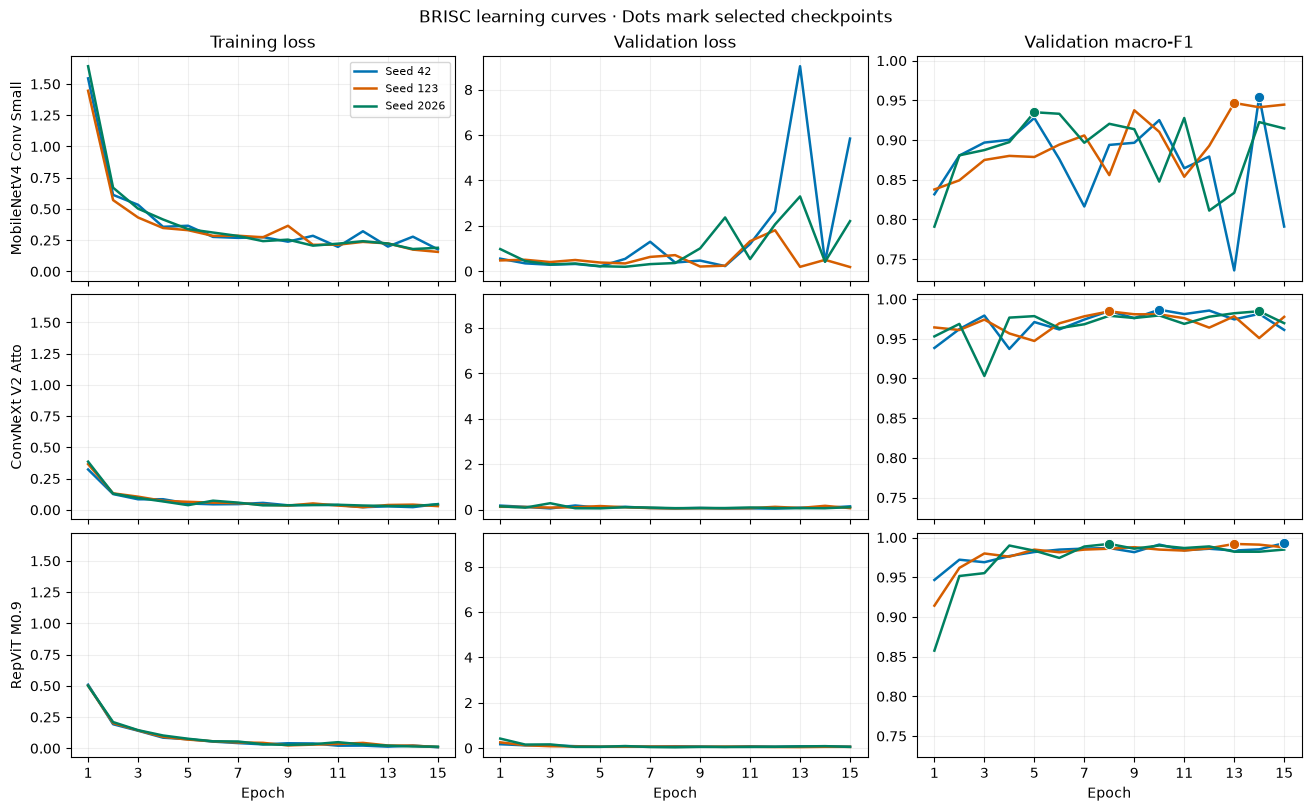

Saved: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\brisc_learning_curves_all_seeds.png


In [5]:
import matplotlib.pyplot as plt

model_order = ["MobileNetV4 Conv Small", "ConvNeXt V2 Atto", "RepViT M0.9"]
seed_colors = {42: "#0072B2", 123: "#D55E00", 2026: "#008060"}
metrics = [
    ("train_loss", "Training loss"),
    ("validation_loss", "Validation loss"),
    ("validation_macro_f1", "Validation macro-F1"),
]
selected_epochs = {
    (run["model"], run["seed"]): run["selected_epoch"] for run in runs
}

fig, axes = plt.subplots(
    3, 3, figsize=(13, 8), sharex=True, sharey="col",
    constrained_layout=True,
)

for row, model in enumerate(model_order):
    for col, (metric, title) in enumerate(metrics):
        ax = axes[row, col]

        for seed, color in seed_colors.items():
            history = histories[(model, seed)]
            epochs = sorted(history)
            values = [history[epoch][metric] for epoch in epochs]
            ax.plot(epochs, values, color=color, linewidth=1.8, label=f"Seed {seed}")

            if metric == "validation_macro_f1":
                chosen = selected_epochs[(model, seed)]
                ax.scatter(chosen, history[chosen][metric], color=color,
                           edgecolor="white", linewidth=0.7, s=55, zorder=3)

        if row == 0:
            ax.set_title(title)
        if col == 0:
            ax.set_ylabel(model)
        if row == 2:
            ax.set_xlabel("Epoch")
        ax.set_xticks([1, 3, 5, 7, 9, 11, 13, 15])
        ax.grid(alpha=0.2)

axes[0, 0].legend(fontsize=8)
fig.suptitle("BRISC learning curves · Dots mark selected checkpoints")

figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
figure_path = figures_dir / "brisc_learning_curves_all_seeds.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

In [6]:
from statistics import mean, stdev

validation_summary = []

for model in model_order:
    model_runs = [run for run in runs if run["model"] == model]
    accuracy = [run["validation_accuracy"] for run in model_runs]
    macro_f1 = [run["validation_macro_f1"] for run in model_runs]

    validation_summary.append({
        "model": model,
        "n_seeds": len(model_runs),
        "validation_accuracy_mean": mean(accuracy),
        "validation_accuracy_sd": stdev(accuracy),
        "validation_macro_f1_mean": mean(macro_f1),
        "validation_macro_f1_sd": stdev(macro_f1),
    })

validation_summary.sort(key=lambda row: row["validation_macro_f1_mean"], reverse=True)

# Save full precision on the original 0–1 scale.
summary_path = tables_dir / "brisc_validation_summary_across_seeds.csv"
with summary_path.open("w", encoding="utf-8", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(validation_summary[0]))
    writer.writeheader()
    writer.writerows(validation_summary)

# Display on a 0–100 scale. SD is in percentage points.
print(f"{'Model':<24} {'Accuracy (mean ± SD)':>22} {'Macro-F1 (mean ± SD)':>22}")
for row in validation_summary:
    acc = f"{100 * row['validation_accuracy_mean']:.2f} ± {100 * row['validation_accuracy_sd']:.2f}"
    f1 = f"{100 * row['validation_macro_f1_mean']:.2f} ± {100 * row['validation_macro_f1_sd']:.2f}"
    print(f"{row['model']:<24} {acc:>22} {f1:>22}")

print("\nSaved:", summary_path)

Model                      Accuracy (mean ± SD)   Macro-F1 (mean ± SD)
RepViT M0.9                        99.21 ± 0.06           99.23 ± 0.06
ConvNeXt V2 Atto                   98.53 ± 0.12           98.53 ± 0.12
MobileNetV4 Conv Small             94.55 ± 0.98           94.55 ± 0.99

Saved: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\brisc_validation_summary_across_seeds.csv


### Validation results across three seeds

RepViT M0.9 achieved the highest mean validation macro-F1 (99.23%), followed by ConvNeXt V2 Atto (98.53%) and MobileNetV4 Conv Small (94.55%). RepViT also showed the smallest variation across seeds, with a macro-F1 standard deviation of 0.06 percentage points.

### Official held-out test evaluation

We will evaluate all nine checkpoints selected in Notebook 09 on the official BRISC test set. The first step is to verify the test manifest, image paths, and class mapping for each checkpoint.

In [7]:
from collections import Counter

dataset_root = project_root / "data" / "raw" / "brisc2025"
test_manifest = project_root / "data" / "processed" / "classification_test_manifest.csv"

with test_manifest.open(encoding="utf-8-sig", newline="") as file:
    test_rows = list(csv.DictReader(file))

expected_counts = {"glioma": 254, "meningioma": 306, "no_tumor": 140, "pituitary": 300}
counts = Counter(row["tumor_label"] for row in test_rows)
assert counts == expected_counts, f"Unexpected test class counts: {dict(counts)}"
assert all(
    row["task"] == "classification" and row["split"] == row["model_split"] == "test"
    for row in test_rows
), "Found a row outside the official classification test split."

test_paths = [dataset_root / row["relative_path"] for row in test_rows]
assert len(set(test_paths)) == len(test_rows), "Repeated image path in test manifest."
missing = [path for path in test_paths if not path.is_file()]
assert not missing, f"{len(missing)} missing test images. First missing path: {missing[:1]}"

class_to_index = None
for run in runs:
    checkpoint_path = project_root / run["checkpoint"]
    state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

    identity = (state["model_id"], state["run_seed"], state["epoch"])
    expected = (run["model_id"], run["seed"], run["selected_epoch"])
    assert identity == expected, f"Checkpoint identity mismatch: {checkpoint_path}"

    mapping = state["class_to_index"]
    assert set(mapping) == set(counts) and set(mapping.values()) == set(range(4)), (
        f"Unexpected class mapping: {mapping}"
    )
    if class_to_index is None:
        class_to_index = dict(mapping)
    assert mapping == class_to_index, f"Class order differs: {checkpoint_path}"
    del state

print(f"Official test scans found: {len(test_paths)}")
for label, index in sorted(class_to_index.items(), key=lambda item: item[1]):
    print(f"  Output {index} → {label:<12} {counts[label]} scans")
print(f"Selected checkpoints with matching identity and class mapping: {len(runs)}/9")

Official test scans found: 1000
  Output 0 → glioma       254 scans
  Output 1 → meningioma   306 scans
  Output 2 → no_tumor     140 scans
  Output 3 → pituitary    300 scans
Selected checkpoints with matching identity and class mapping: 9/9


In [8]:
import json

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import Normalize
from torchvision.transforms.functional import pil_to_tensor

config_path = project_root / "data" / "processed" / "brisc_preprocessing_config.json"
with config_path.open(encoding="utf-8-sig") as file:
    preprocessing_config = json.load(file)

image_size = preprocessing_config["classification"]["default_input_size"]
assert image_size == 224, f"Expected Notebook 09 input size 224, found {image_size}"

checkpoint_normalize = Normalize(
    mean=(0.485, 0.456, 0.406),
    std=(0.229, 0.224, 0.225),
)

class BRISCTestDataset(Dataset):
    def __len__(self):
        return len(test_rows)

    def __getitem__(self, index):
        row = test_rows[index]
        with Image.open(test_paths[index]) as image:
            gray = image.convert("L")
            resized = gray.resize(
                (image_size, image_size),
                resample=Image.Resampling.BILINEAR,
            )

        single_channel = pil_to_tensor(resized).to(torch.float32) / 255.0
        image_tensor = checkpoint_normalize(single_channel.repeat(3, 1, 1))
        return image_tensor, class_to_index[row["tumor_label"]], index

test_loader = DataLoader(
    BRISCTestDataset(),
    batch_size=8,
    shuffle=False,
    drop_last=False,
    num_workers=0,
)

images, labels, indices = next(iter(test_loader))
assert images.shape == (8, 3, 224, 224)
assert images.dtype == torch.float32 and torch.isfinite(images).all().item()
assert indices.tolist() == list(range(8))
assert labels.tolist() == [class_to_index[row["tumor_label"]] for row in test_rows[:8]]

print(f"Test loader: {len(test_loader.dataset)} scans in {len(test_loader)} batches")
print(f"First batch shape: {tuple(images.shape)}")
print(f"First batch manifest indices: {indices.tolist()}")
print("First batch passed the tensor and label checks.")

Test loader: 1000 scans in 125 batches
First batch shape: (8, 3, 224, 224)
First batch manifest indices: [0, 1, 2, 3, 4, 5, 6, 7]
First batch passed the tensor and label checks.


In [9]:
import timm
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
prediction_dir = project_root / "outputs" / "predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

index_to_class = {index: label for label, index in class_to_index.items()}
class_names = [index_to_class[i] for i in range(len(class_to_index))]
print(f"Inference device: {device}", flush=True)


@torch.inference_mode()
def evaluate_fixed_checkpoint(run):
    checkpoint_path = project_root / run["checkpoint"]
    state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

    model = timm.create_model(
        run["model_id"], pretrained=False, num_classes=len(class_names)
    )
    model.load_state_dict(state["model_state_dict"], strict=True)
    del state
    model.to(device).eval()

    predictions = []
    for images, labels, indices in test_loader:
        logits = model(images.to(device))
        assert logits.shape == (len(indices), len(class_names))
        assert torch.isfinite(logits).all().item(), "Non-finite test logits"

        probabilities = logits.softmax(dim=1).cpu().tolist()
        predicted_indices = logits.argmax(dim=1).cpu().tolist()
        losses = F.cross_entropy(logits, labels.to(device), reduction="none").cpu().tolist()

        for i, scan_index in enumerate(indices.tolist()):
            scan = test_rows[scan_index]
            true_label = index_to_class[labels[i].item()]
            assert true_label == scan["tumor_label"]

            row = {
                "model": run["model"],
                "seed": run["seed"],
                "selected_epoch": run["selected_epoch"],
                "manifest_index": scan_index,
                "relative_path": scan["relative_path"],
                "true_label": true_label,
                "predicted_label": index_to_class[predicted_indices[i]],
                "test_loss": losses[i],
            }
            for label, probability in zip(class_names, probabilities[i]):
                row[f"prob_{label}"] = probability
            predictions.append(row)

    # Publish the CSV only after every manifest row appears exactly once, in order.
    assert [row["manifest_index"] for row in predictions] == list(range(len(test_rows)))
    filename = f"{run['model_id']}_seed{run['seed']}_test_predictions.csv"
    output_path = prediction_dir / filename
    temporary_path = output_path.with_suffix(".tmp")
    with temporary_path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(predictions[0]))
        writer.writeheader()
        writer.writerows(predictions)
    temporary_path.replace(output_path)
    return output_path


test_prediction_files = {}
for number, run in enumerate(runs, start=1):
    print(
        f"[{number}/{len(runs)}] {run['model']} | seed {run['seed']} | "
        f"epoch {run['selected_epoch']} ...",
        flush=True,
    )
    path = evaluate_fixed_checkpoint(run)
    test_prediction_files[(run["model"], run["seed"])] = path
    print(f"  Saved {len(test_rows)} predictions.", flush=True)

print(f"\nCompleted: {len(test_prediction_files)}/9 test prediction files")
print("Folder:", prediction_dir)

C:\Users\HP\miniconda3\envs\brainxai-train\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Inference device: cuda
[1/9] RepViT M0.9 | seed 42 | epoch 15 ...
  Saved 1000 predictions.
[2/9] ConvNeXt V2 Atto | seed 42 | epoch 10 ...
  Saved 1000 predictions.
[3/9] MobileNetV4 Conv Small | seed 42 | epoch 14 ...
  Saved 1000 predictions.
[4/9] RepViT M0.9 | seed 123 | epoch 13 ...
  Saved 1000 predictions.
[5/9] ConvNeXt V2 Atto | seed 123 | epoch 8 ...
  Saved 1000 predictions.
[6/9] MobileNetV4 Conv Small | seed 123 | epoch 13 ...
  Saved 1000 predictions.
[7/9] MobileNetV4 Conv Small | seed 2026 | epoch 5 ...
  Saved 1000 predictions.
[8/9] ConvNeXt V2 Atto | seed 2026 | epoch 14 ...
  Saved 1000 predictions.
[9/9] RepViT M0.9 | seed 2026 | epoch 8 ...
  Saved 1000 predictions.

Completed: 9/9 test prediction files
Folder: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\predictions


In [10]:
test_results = []

for run in sorted(runs, key=lambda r: (r["model"], r["seed"])):
    path = test_prediction_files[(run["model"], run["seed"])]
    with path.open(encoding="utf-8", newline="") as file:
        predictions = list(csv.DictReader(file))

    assert len(predictions) == len(test_rows), f"Wrong scan count in {path.name}"
    pairs = Counter()

    for index, (pred, scan) in enumerate(zip(predictions, test_rows)):
        assert (
            pred["model"] == run["model"]
            and int(pred["seed"]) == run["seed"]
            and int(pred["selected_epoch"]) == run["selected_epoch"]
            and int(pred["manifest_index"]) == index
            and pred["relative_path"] == scan["relative_path"]
            and pred["true_label"] == scan["tumor_label"]
            and pred["predicted_label"] in class_names
        ), f"Prediction mismatch in {path.name}, row {index}"

        pairs[(pred["true_label"], pred["predicted_label"])] += 1

    per_class_f1 = {}
    for label in class_names:
        true_positive = pairs[(label, label)]
        actual_count = sum(pairs[(label, other)] for other in class_names)
        predicted_count = sum(pairs[(other, label)] for other in class_names)
        per_class_f1[label] = 2 * true_positive / (actual_count + predicted_count)

    correct = sum(pairs[(label, label)] for label in class_names)
    test_results.append({
        "model": run["model"],
        "seed": run["seed"],
        "selected_epoch": run["selected_epoch"],
        "test_scans": len(predictions),
        "correct": correct,
        "test_accuracy": correct / len(predictions),
        "test_macro_f1": mean(per_class_f1.values()),
        "test_loss": mean(float(p["test_loss"]) for p in predictions),
        **{f"f1_{label}": score for label, score in per_class_f1.items()},
    })

output_path = tables_dir / "brisc_test_results_per_checkpoint.csv"
with output_path.open("w", encoding="utf-8", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(test_results[0]))
    writer.writeheader()
    writer.writerows(test_results)

print(f"{'Model':<24} {'Seed':>5} {'Epoch':>5} {'Correct':>9} {'Accuracy':>10} {'Macro-F1':>10}")
for row in test_results:
    correct_text = f"{row['correct']}/{row['test_scans']}"
    print(
        f"{row['model']:<24} {row['seed']:>5} {row['selected_epoch']:>5} "
        f"{correct_text:>9} {row['test_accuracy']:>10.2%} {row['test_macro_f1']:>10.2%}"
    )

print("\nSaved:", output_path)

Model                     Seed Epoch   Correct   Accuracy   Macro-F1
ConvNeXt V2 Atto            42    10  963/1000     96.30%     96.43%
ConvNeXt V2 Atto           123     8  962/1000     96.20%     95.67%
ConvNeXt V2 Atto          2026    14  970/1000     97.00%     96.88%
MobileNetV4 Conv Small      42    14  882/1000     88.20%     87.61%
MobileNetV4 Conv Small     123    13  901/1000     90.10%     90.30%
MobileNetV4 Conv Small    2026     5  835/1000     83.50%     82.72%
RepViT M0.9                 42    15  970/1000     97.00%     96.76%
RepViT M0.9                123    13  963/1000     96.30%     95.76%
RepViT M0.9               2026     8  963/1000     96.30%     96.10%

Saved: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\brisc_test_results_per_checkpoint.csv


In [11]:
from statistics import mean, stdev

test_summary = []

for model in model_order:
    model_runs = [row for row in test_results if row["model"] == model]
    assert sorted(row["seed"] for row in model_runs) == [42, 123, 2026]
    assert all(row["test_scans"] == 1000 for row in model_runs)

    accuracy = [row["test_accuracy"] for row in model_runs]
    macro_f1 = [row["test_macro_f1"] for row in model_runs]

    test_summary.append({
        "model": model,
        "n_seeds": len(model_runs),
        "test_accuracy_mean": mean(accuracy),
        "test_accuracy_sd": stdev(accuracy),
        "test_macro_f1_mean": mean(macro_f1),
        "test_macro_f1_sd": stdev(macro_f1),
    })

test_summary.sort(key=lambda row: row["test_macro_f1_mean"], reverse=True)

output_path = tables_dir / "brisc_test_summary_across_seeds.csv"
with output_path.open("w", encoding="utf-8", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(test_summary[0]))
    writer.writeheader()
    writer.writerows(test_summary)

print(f"{'Model':<24} {'Accuracy (mean ± SD)':>22} {'Macro-F1 (mean ± SD)':>22}")
for row in test_summary:
    acc = f"{100 * row['test_accuracy_mean']:.2f} ± {100 * row['test_accuracy_sd']:.2f}"
    f1 = f"{100 * row['test_macro_f1_mean']:.2f} ± {100 * row['test_macro_f1_sd']:.2f}"
    print(f"{row['model']:<24} {acc:>22} {f1:>22}")

print("\nSaved:", output_path)

Model                      Accuracy (mean ± SD)   Macro-F1 (mean ± SD)
ConvNeXt V2 Atto                   96.50 ± 0.44           96.33 ± 0.61
RepViT M0.9                        96.53 ± 0.40           96.21 ± 0.51
MobileNetV4 Conv Small             87.27 ± 3.40           86.88 ± 3.84

Saved: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\tables\brisc_test_summary_across_seeds.csv


## Notebook 10 conclusion — Validation and held-out test results

We compared MobileNetV4 Conv Small, ConvNeXt V2 Atto, and RepViT M0.9 across seeds 42, 123, and 2026. For each run, we selected the checkpoint with the highest macro-F1 on the 973-scan validation set, then evaluated that fixed checkpoint on the same 1,000 official held-out test scans.

| Model | Validation accuracy (%) | Validation macro-F1 (%) | Test accuracy (%) | Test macro-F1 (%) |
|---|---:|---:|---:|---:|
| ConvNeXt V2 Atto | 98.53 ± 0.12 | 98.53 ± 0.12 | 96.50 ± 0.44 | 96.33 ± 0.61 |
| RepViT M0.9 | 99.21 ± 0.06 | 99.23 ± 0.06 | 96.53 ± 0.40 | 96.21 ± 0.51 |
| MobileNetV4 Conv Small | 94.55 ± 0.98 | 94.55 ± 0.99 | 87.27 ± 3.40 | 86.88 ± 3.84 |

Values are means across three training seeds. The sample standard deviation (±) describes variation across those runs in percentage points.

RepViT led on both validation metrics. On the held-out test set, RepViT and ConvNeXt performed similarly. RepViT had the highest mean accuracy by 0.03 percentage points, while ConvNeXt had the highest mean macro-F1 by 0.12 percentage points. Which model ranked first depended on the metric.

MobileNetV4 had the lowest mean test scores and the widest variation across seeds. Its mean macro-F1 fell from 94.55% on validation to 86.88% on test, a drop of 7.67 percentage points.

The saved learning curves, per-scan predictions, and result tables complete the classification evaluation. The next phase will compare XAI explanations for the fixed checkpoints.

In [12]:
import csv
import io
import json
import platform
import zipfile
from importlib.metadata import version
from pathlib import Path, PureWindowsPath

import torch

project_root = Path(r"C:\Users\HP\Documents\Projects\Brain_Tumor_XAI")
tables_dir = project_root / "outputs" / "tables"
processed_dir = project_root / "data" / "processed"
dataset_root = project_root / "data" / "raw" / "brisc2025"
handoff_dir = project_root / "outputs" / "handoff"
handoff_dir.mkdir(parents=True, exist_ok=True)

zip_path = handoff_dir / "Group8_BRISC_Model_Handoff.zip"
temporary_zip = zip_path.with_suffix(".tmp")


def read_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as file:
        return list(csv.DictReader(file))


# Recover the exact selected runs and test rows from the saved files.
summary_files = [
    tables_dir / f"brisc_seed{seed}_validation_summary.csv"
    for seed in (42, 123, 2026)
]
runs_to_export = [row for path in summary_files for row in read_csv(path)]
manifest_path = processed_dir / "classification_test_manifest.csv"
handoff_test_rows = read_csv(manifest_path)

model_ids = {row["model_id"] for row in runs_to_export}
expected_runs = {(model_id, seed) for model_id in model_ids for seed in (42, 123, 2026)}
actual_runs = {(row["model_id"], int(row["seed"])) for row in runs_to_export}
assert len(model_ids) == 3 and len(runs_to_export) == 9 and actual_runs == expected_runs
assert len(handoff_test_rows) == 1000
assert len({row["relative_path"] for row in handoff_test_rows}) == 1000

reference_files = [
    *summary_files,
    manifest_path,
    processed_dir / "brisc_preprocessing_config.json",
    tables_dir / "brisc_validation_summary_across_seeds.csv",
    tables_dir / "brisc_test_results_per_checkpoint.csv",
    tables_dir / "brisc_test_summary_across_seeds.csv",
    project_root / "outputs" / "figures" / "brisc_learning_curves_all_seeds.png",
    project_root / "notebooks" / "10_BRISC_Learning_Curves_and_Test_Evaluation.ipynb",
]

# Generate a fresh notebook with portable paths and no saved execution state.
starter_setup = '''from pathlib import Path, PureWindowsPath
import csv
import json
import torch
import timm
from PIL import Image
from torchvision.transforms import Normalize
from torchvision.transforms.functional import pil_to_tensor

# Enter the extracted folder containing model_index.json.
# In Colab, mount Google Drive first if the folder is on Drive.
root = Path(input("Extracted handoff folder: ").strip().strip('"')).expanduser()
models = json.loads((root / "model_index.json").read_text(encoding="utf-8"))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
for index, entry in enumerate(models):
    print(index, entry["model"], "seed", entry["seed"], "epoch", entry["selected_epoch"])
'''

starter_predict = '''# Change these indices to try another checkpoint or test scan.
model_number = 0
scan_number = 0

entry = models[model_number]
saved = torch.load(root / entry["weights"], map_location="cpu", weights_only=True)
class_to_index = saved["class_to_index"]
index_to_class = {value: key for key, value in class_to_index.items()}
model = timm.create_model(saved["model_id"], pretrained=False, num_classes=len(class_to_index))
model.load_state_dict(saved["model_state_dict"], strict=True)
model.to(device).eval()

with (root / "data/processed/classification_test_manifest.csv").open(
    encoding="utf-8-sig", newline=""
) as file:
    rows = list(csv.DictReader(file))
row = rows[scan_number]
relative = Path(*PureWindowsPath(row["relative_path"]).parts)
image_path = root / "data/raw/brisc2025" / relative
config = json.loads((root / "data/processed/brisc_preprocessing_config.json").read_text())
size = config["classification"]["default_input_size"]

with Image.open(image_path) as image:
    gray = image.convert("L").resize((size, size), Image.Resampling.BILINEAR)
x = pil_to_tensor(gray).float().div(255).repeat(3, 1, 1)
normalize = Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
x = normalize(x).unsqueeze(0).to(device)

# Disable gradients for this prediction check only. Grad-CAM needs a fresh
# forward pass with gradients enabled.
with torch.no_grad():
    predicted = index_to_class[model(x).argmax(dim=1).item()]

with (root / entry["reference_predictions"]).open(encoding="utf-8", newline="") as file:
    reference = next(r for r in csv.DictReader(file) if r["relative_path"] == row["relative_path"])

print("Scan:", relative.name)
print("True label:", row["tumor_label"])
print("This device:", predicted)
print("Windows reference:", reference["predicted_label"])
print("Labels match:", predicted == reference["predicted_label"])
'''


def code_cell(source, cell_id):
    return {
        "cell_type": "code", "id": cell_id, "metadata": {},
        "execution_count": None, "outputs": [], "source": source.splitlines(True),
    }


starter = {
    "nbformat": 4,
    "nbformat_minor": 5,
    "metadata": {"kernelspec": {
        "display_name": "Python 3", "language": "python", "name": "python3"
    }},
    "cells": [
        code_cell(starter_setup, "load-handoff"),
        code_cell(starter_predict, "check-prediction"),
    ],
}

readme = """Group 8 BRISC model handoff

1. Extract the ZIP into one folder. Keep its subfolders together.
2. Open START_HERE.ipynb in local JupyterLab or Google Colab.
3. Use an environment with torch, torchvision, timm and Pillow.
   windows_environment.txt records the versions used for the original evaluation.
4. Run the first cell and enter the folder containing model_index.json.
5. Run the second cell to compare one prediction with its Windows reference.

model_index.json maps all nine exported weights to their reference predictions.
The 1,000 classification test images are included. Expert segmentation masks
must be obtained separately and matched to the corresponding scans for mask analysis.
Notebook 10 is the original Windows evaluation record and uses the original
training checkpoint paths. START_HERE.ipynb uses the portable exported weights.
"""

versions = [f"Python {platform.python_version()}", platform.platform()]
versions += [
    f"{package}=={version(package)}"
    for package in ("torch", "torchvision", "timm", "Pillow", "matplotlib")
]

model_index = []
with zipfile.ZipFile(temporary_zip, "w", allowZip64=True) as archive:
    for path in reference_files:
        archive.write(path, path.relative_to(project_root).as_posix())

    for row in runs_to_export:
        seed = int(row["seed"])
        epoch = int(row["selected_epoch"])
        model_id = row["model_id"]
        state = torch.load(
            project_root / row["checkpoint"], map_location="cpu", weights_only=True
        )
        assert (state["model_id"], state["run_seed"], state["epoch"]) == (
            model_id, seed, epoch
        )

        weights_name = f"models/{model_id}_seed{seed}_epoch{epoch:02d}.pt"
        payload = {
            key: state[key] for key in
            ("model_id", "run_seed", "epoch", "class_to_index", "model_state_dict")
        }
        with io.BytesIO() as buffer:
            torch.save(payload, buffer)
            archive.writestr(weights_name, buffer.getvalue())
        del state, payload

        prediction_path = (
            project_root / "outputs" / "predictions"
            / f"{model_id}_seed{seed}_test_predictions.csv"
        )
        prediction_name = prediction_path.relative_to(project_root).as_posix()
        archive.write(prediction_path, prediction_name)
        model_index.append({
            "model": row["model"], "model_id": model_id, "seed": seed,
            "selected_epoch": epoch, "weights": weights_name,
            "reference_predictions": prediction_name,
        })
        print(f"Packaged {row['model']}, seed {seed}, epoch {epoch}", flush=True)

    print("Adding 1,000 test images...", flush=True)
    for row in handoff_test_rows:
        relative = Path(*PureWindowsPath(row["relative_path"]).parts)
        path = dataset_root / relative
        archive.write(path, path.relative_to(project_root).as_posix())

    archive.writestr("model_index.json", json.dumps(model_index, indent=2))
    archive.writestr("START_HERE.ipynb", json.dumps(starter, indent=1))
    archive.writestr("README_FIRST.txt", readme)
    archive.writestr("windows_environment.txt", "\n".join(versions) + "\n")

print("Checking ZIP integrity...", flush=True)
with zipfile.ZipFile(temporary_zip) as archive:
    bad_file = archive.testzip()
    assert bad_file is None, f"ZIP integrity check failed for {bad_file}"
    names = set(archive.namelist())
    assert all(entry["weights"] in names for entry in model_index)
    assert all(entry["reference_predictions"] in names for entry in model_index)

temporary_zip.replace(zip_path)
print(f"Ready to share: {zip_path}")
print(f"Size: {zip_path.stat().st_size / 1024**2:.1f} MiB")
print("Included: 9 model exports, 9 prediction CSVs, 1,000 test scans, and START_HERE.ipynb")

Packaged RepViT M0.9, seed 42, epoch 15
Packaged ConvNeXt V2 Atto, seed 42, epoch 10
Packaged MobileNetV4 Conv Small, seed 42, epoch 14
Packaged RepViT M0.9, seed 123, epoch 13
Packaged ConvNeXt V2 Atto, seed 123, epoch 8
Packaged MobileNetV4 Conv Small, seed 123, epoch 13
Packaged MobileNetV4 Conv Small, seed 2026, epoch 5
Packaged ConvNeXt V2 Atto, seed 2026, epoch 14
Packaged RepViT M0.9, seed 2026, epoch 8
Adding 1,000 test images...
Checking ZIP integrity...
Ready to share: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\handoff\Group8_BRISC_Model_Handoff.zip
Size: 147.4 MiB
Included: 9 model exports, 9 prediction CSVs, 1,000 test scans, and START_HERE.ipynb
